In [ ]:
#!pip3 install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu118

In [ ]:
#!pip install datasets transformers evaluate accelerate

In [1]:
import os
os.chdir('./woojh')
os.getcwd()

'/home/jovyan/woojh'

In [2]:
from glob import glob
DATA_DIR = "./atlantis"

train_images = sorted(glob(os.path.join(DATA_DIR, "images/train/*/*")))
train_masks = sorted(glob(os.path.join(DATA_DIR, "masks/train/*/*")))
val_images = sorted(glob(os.path.join(DATA_DIR, "images/val/*/*")))
val_masks = sorted(glob(os.path.join(DATA_DIR, "masks/val/*/*")))
test_images = sorted(glob(os.path.join(DATA_DIR, "images/test/*/*")))
test_masks = sorted(glob(os.path.join(DATA_DIR, "masks/test/*/*")))

In [3]:
from datasets import Image, Dataset
def make_dataset(images, masks):
    ds = Dataset.from_dict({"pixel_values": images, "label": masks})
    ds = ds.cast_column("pixel_values", Image())
    ds = ds.cast_column("label", Image())
    return ds

In [4]:
train_ds = make_dataset(train_images, train_masks)
val_ds = make_dataset(val_images, val_masks)
test_ds = make_dataset(test_images, test_masks)
print(train_ds)
print(val_ds)
print(test_ds)

Dataset({
    features: ['pixel_values', 'label'],
    num_rows: 3364
})
Dataset({
    features: ['pixel_values', 'label'],
    num_rows: 535
})
Dataset({
    features: ['pixel_values', 'label'],
    num_rows: 1296
})


In [5]:
import json

# Load JSON file
label2id = {"none":0}
id2label = {0: "none"}
with open(os.path.join(DATA_DIR, 'labels_info.json')) as f:
    labels = json.load(f)
    for idx, label in enumerate(labels, start=1):
        label2id[label["name"]] = idx
        id2label[idx] = label["name"]
print(label2id)
print(id2label)

{'none': 0, 'bicycle': 1, 'boat': 2, 'breakwater': 3, 'bridge': 4, 'building': 5, 'bus': 6, 'canal': 7, 'car': 8, 'cliff': 9, 'culvert': 10, 'cypress_tree': 11, 'dam': 12, 'ditch': 13, 'fence': 14, 'fire_hydrant': 15, 'fjord': 16, 'flood': 17, 'glaciers': 18, 'hot_spring': 19, 'lake': 20, 'levee': 21, 'lighthouse': 22, 'mangrove': 23, 'marsh': 24, 'motorcycle': 25, 'offshore_platform': 26, 'parking_meter': 27, 'person': 28, 'pier': 29, 'pipeline': 30, 'pole': 31, 'puddle': 32, 'rapids': 33, 'reservoir': 34, 'river': 35, 'river_delta': 36, 'road': 37, 'sea': 38, 'ship': 39, 'shoreline': 40, 'sidewalk': 41, 'sky': 42, 'snow': 43, 'spillway': 44, 'swimming_pool': 45, 'terrain': 46, 'traffic_sign': 47, 'train': 48, 'truck': 49, 'umbrella': 50, 'vegetation': 51, 'wall': 52, 'water_tower': 53, 'water_well': 54, 'waterfall': 55, 'wetland': 56}
{0: 'none', 1: 'bicycle', 2: 'boat', 3: 'breakwater', 4: 'bridge', 5: 'building', 6: 'bus', 7: 'canal', 8: 'car', 9: 'cliff', 10: 'culvert', 11: 'cypre

In [6]:
from torchvision.transforms import ColorJitter
from transformers import SegformerFeatureExtractor

feature_extractor = SegformerFeatureExtractor()
jitter = ColorJitter(brightness=0.25, contrast=0.25, saturation=0.25, hue=0.1) 

def train_transforms(example_batch):
    images = [jitter(x.convert("RGB")) for x in example_batch['pixel_values']]
    labels = [x for x in example_batch['label']]
    inputs = feature_extractor(images, labels)
    return inputs


def val_and_test_transforms(example_batch):
    images = [x.convert("RGB") for x in example_batch['pixel_values']]
    labels = [x for x in example_batch['label']]
    inputs = feature_extractor(images, labels)
    return inputs

/opt/conda/lib/python3.11/site-packages/transformers/models/segformer/feature_extraction_segformer.py:28: FutureWarning: The class SegformerFeatureExtractor is deprecated and will be removed in version 5 of Transformers. Please use SegformerImageProcessor instead.
  warnings.warn(


In [ ]:
# Set transforms
train_ds.set_transform(train_transforms)
val_ds.set_transform(val_and_test_transforms)
test_ds.set_transform(val_and_test_transforms)

In [7]:
from transformers import SegformerForSemanticSegmentation

# model_name = "segformer-b0" 
# pretrained_model_name = "nvidia/mit-b0"

# model_name = "segformer-b1" 
# pretrained_model_name = "nvidia/mit-b1"
# pretrained_model_name = model_name + "/checkpoint-10540"

# model_name = "segformer-b2" 
# pretrained_model_name = "nvidia/mit-b2"
# pretrained_model_name = model_name + "/checkpoint-21200"

model_name = "segformer-b5" 
# pretrained_model_name = "nvidia/mit-b5"
pretrained_model_name = model_name + "/checkpoint-22080"

model = SegformerForSemanticSegmentation.from_pretrained(
    pretrained_model_name,
    id2label=id2label,
    label2id=label2id
)

In [8]:
from transformers import TrainingArguments

epochs = 200
lr = 0.00006
batch_size = 8

hub_model_id = "segformer-b0-finetuned-segments-sidewalk-2"

training_args = TrainingArguments(
    model_name,
    learning_rate=lr,
    num_train_epochs=epochs,
    per_device_train_batch_size=batch_size,
    per_device_eval_batch_size=batch_size,
    save_total_limit=3,
    evaluation_strategy="steps",
    save_strategy="steps",
    save_steps=40,
    eval_steps=40,
    logging_steps=1,
    eval_accumulation_steps=5,
    load_best_model_at_end=True,
    hub_model_id=hub_model_id,
    hub_strategy="end",
)

In [ ]:
import torch
from torch import nn
import evaluate

metric = evaluate.load("mean_iou")

def compute_metrics(eval_pred):
  with torch.no_grad():
    logits, labels = eval_pred
    logits_tensor = torch.from_numpy(logits)
    # scale the logits to the size of the label
    logits_tensor = nn.functional.interpolate(
        logits_tensor,
        size=labels.shape[-2:],
        mode="bilinear",
        align_corners=False,
    ).argmax(dim=1)

    pred_labels = logits_tensor.detach().cpu().numpy()
    # currently using _compute instead of compute
    # see this issue for more info: https://github.com/huggingface/evaluate/pull/328#issuecomment-1286866576
    metrics = metric._compute(
            predictions=pred_labels,
            references=labels,
            num_labels=len(id2label),
            ignore_index=0,
            reduce_labels=feature_extractor.do_reduce_labels,
        )
    
    # add per category metrics as individual key-value pairs
    per_category_accuracy = metrics.pop("per_category_accuracy").tolist()
    per_category_iou = metrics.pop("per_category_iou").tolist()

    metrics.update({f"accuracy_{id2label[i]}": v for i, v in enumerate(per_category_accuracy)})
    metrics.update({f"iou_{id2label[i]}": v for i, v in enumerate(per_category_iou)})
    
    return metrics


In [ ]:
from transformers import Trainer

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    compute_metrics=compute_metrics,
)

In [ ]:
trainer.train()

In [9]:
def hex_to_rgb(hex):
    hex = hex.lstrip('#')
    h_length = len(hex)
    return [int(hex[i:i+h_length//3], 16) for i in range(0, h_length, h_length//3)]

def atlantis_palette():
    with open('./atlantis/labels_info.json') as f:
        colormap_json = json.load(f)

    # Create colormap from JSON
    label_names = ["none"]
    colormap = [[0, 0, 0]]
    for item in colormap_json:
        label_names.append(item['name'])
        colormap.append(item['color'])

    return label_names, colormap

label_names, atlantis_palette = atlantis_palette()
label_names

['none',
 'bicycle',
 'boat',
 'breakwater',
 'bridge',
 'building',
 'bus',
 'canal',
 'car',
 'cliff',
 'culvert',
 'cypress_tree',
 'dam',
 'ditch',
 'fence',
 'fire_hydrant',
 'fjord',
 'flood',
 'glaciers',
 'hot_spring',
 'lake',
 'levee',
 'lighthouse',
 'mangrove',
 'marsh',
 'motorcycle',
 'offshore_platform',
 'parking_meter',
 'person',
 'pier',
 'pipeline',
 'pole',
 'puddle',
 'rapids',
 'reservoir',
 'river',
 'river_delta',
 'road',
 'sea',
 'ship',
 'shoreline',
 'sidewalk',
 'sky',
 'snow',
 'spillway',
 'swimming_pool',
 'terrain',
 'traffic_sign',
 'train',
 'truck',
 'umbrella',
 'vegetation',
 'wall',
 'water_tower',
 'water_well',
 'waterfall',
 'wetland']

In [10]:
import numpy as np

def get_seg_overlay(image, seg):
    color_seg = np.zeros((seg.shape[0], seg.shape[1], 3), dtype=np.uint8) # height, width, 3
    palette = np.array(atlantis_palette)
    select_color = dict()
    for label, color in enumerate(palette):
        color_seg[seg == label, :] = color
        if (seg == label).any():
            select_color[label_names[label]] = color

    # Show image + mask
    img = np.array(image) * 0.5 + color_seg * 0.5
    img = img.astype(np.uint8)

    return img, select_color

In [11]:
import matplotlib.pyplot as plt
from torch import nn

def compare(dataset, image_idx):
    # 세그먼테이션할 이미지 선택
    image = dataset[image_idx]['pixel_values']
    gt_seg = dataset[image_idx]['label']

    # 세그먼테이션 실행
    inputs = feature_extractor(images=image, return_tensors="pt")
    outputs = model(**inputs)
    logits = outputs.logits  # shape (batch_size, num_labels, height/4, width/4)

    # 원래 이미지 사이즈로 복원
    upsampled_logits = nn.functional.interpolate(
        logits,
        size=image.size[::-1], # (height, width)
        mode='bilinear',
        align_corners=False
    )

    # 세그먼테이션 결과 오버레이
    pred_seg = upsampled_logits.argmax(dim=1)[0]
    pred_img, pred_select_color = get_seg_overlay(image, pred_seg)
    gt_img, gt_select_color = get_seg_overlay(image, np.array(gt_seg))

    # 차트 생성
    f, axs = plt.subplots(2, 2, figsize=(10, 6))
    f.set_figheight(30)
    f.set_figwidth(50)

    axs[0][0].set_title("Prediction", {'fontsize': 80})
    axs[0][0].imshow(pred_img)
    axs[0][1].set_title("Ground truth", {'fontsize': 80})
    axs[0][1].imshow(gt_img)

    # Prediction의 레전드 생성
    pred_patches = []
    for label, color in pred_select_color.items():
        line2D = plt.Line2D([0], [0], marker='o', color=color/255, label=label, markersize=30, markerfacecolor=color/255)
        pred_patches.append(line2D)
    axs[1][0].axis('off')
    axs[1][0].legend(handles=pred_patches, loc='upper center', ncol=4, fontsize=32)

    # Ground truth의 레전드 생성
    gt_patches = []
    for label, color in gt_select_color.items():
        line2D = plt.Line2D([0], [0], marker='o', color=color/255, label=label, markersize=30, markerfacecolor=color/255)
        gt_patches.append(line2D)
    axs[1][1].axis('off')
    axs[1][1].legend(handles=gt_patches, loc='upper center', ncol=4, fontsize=32)

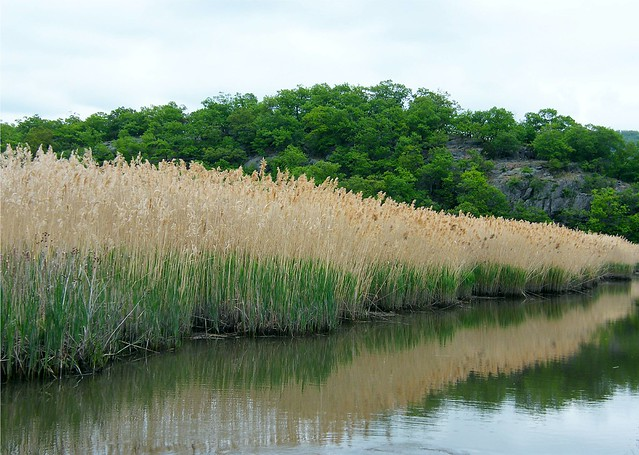

In [49]:
idx = 611
image = test_ds[idx]['pixel_values']
image

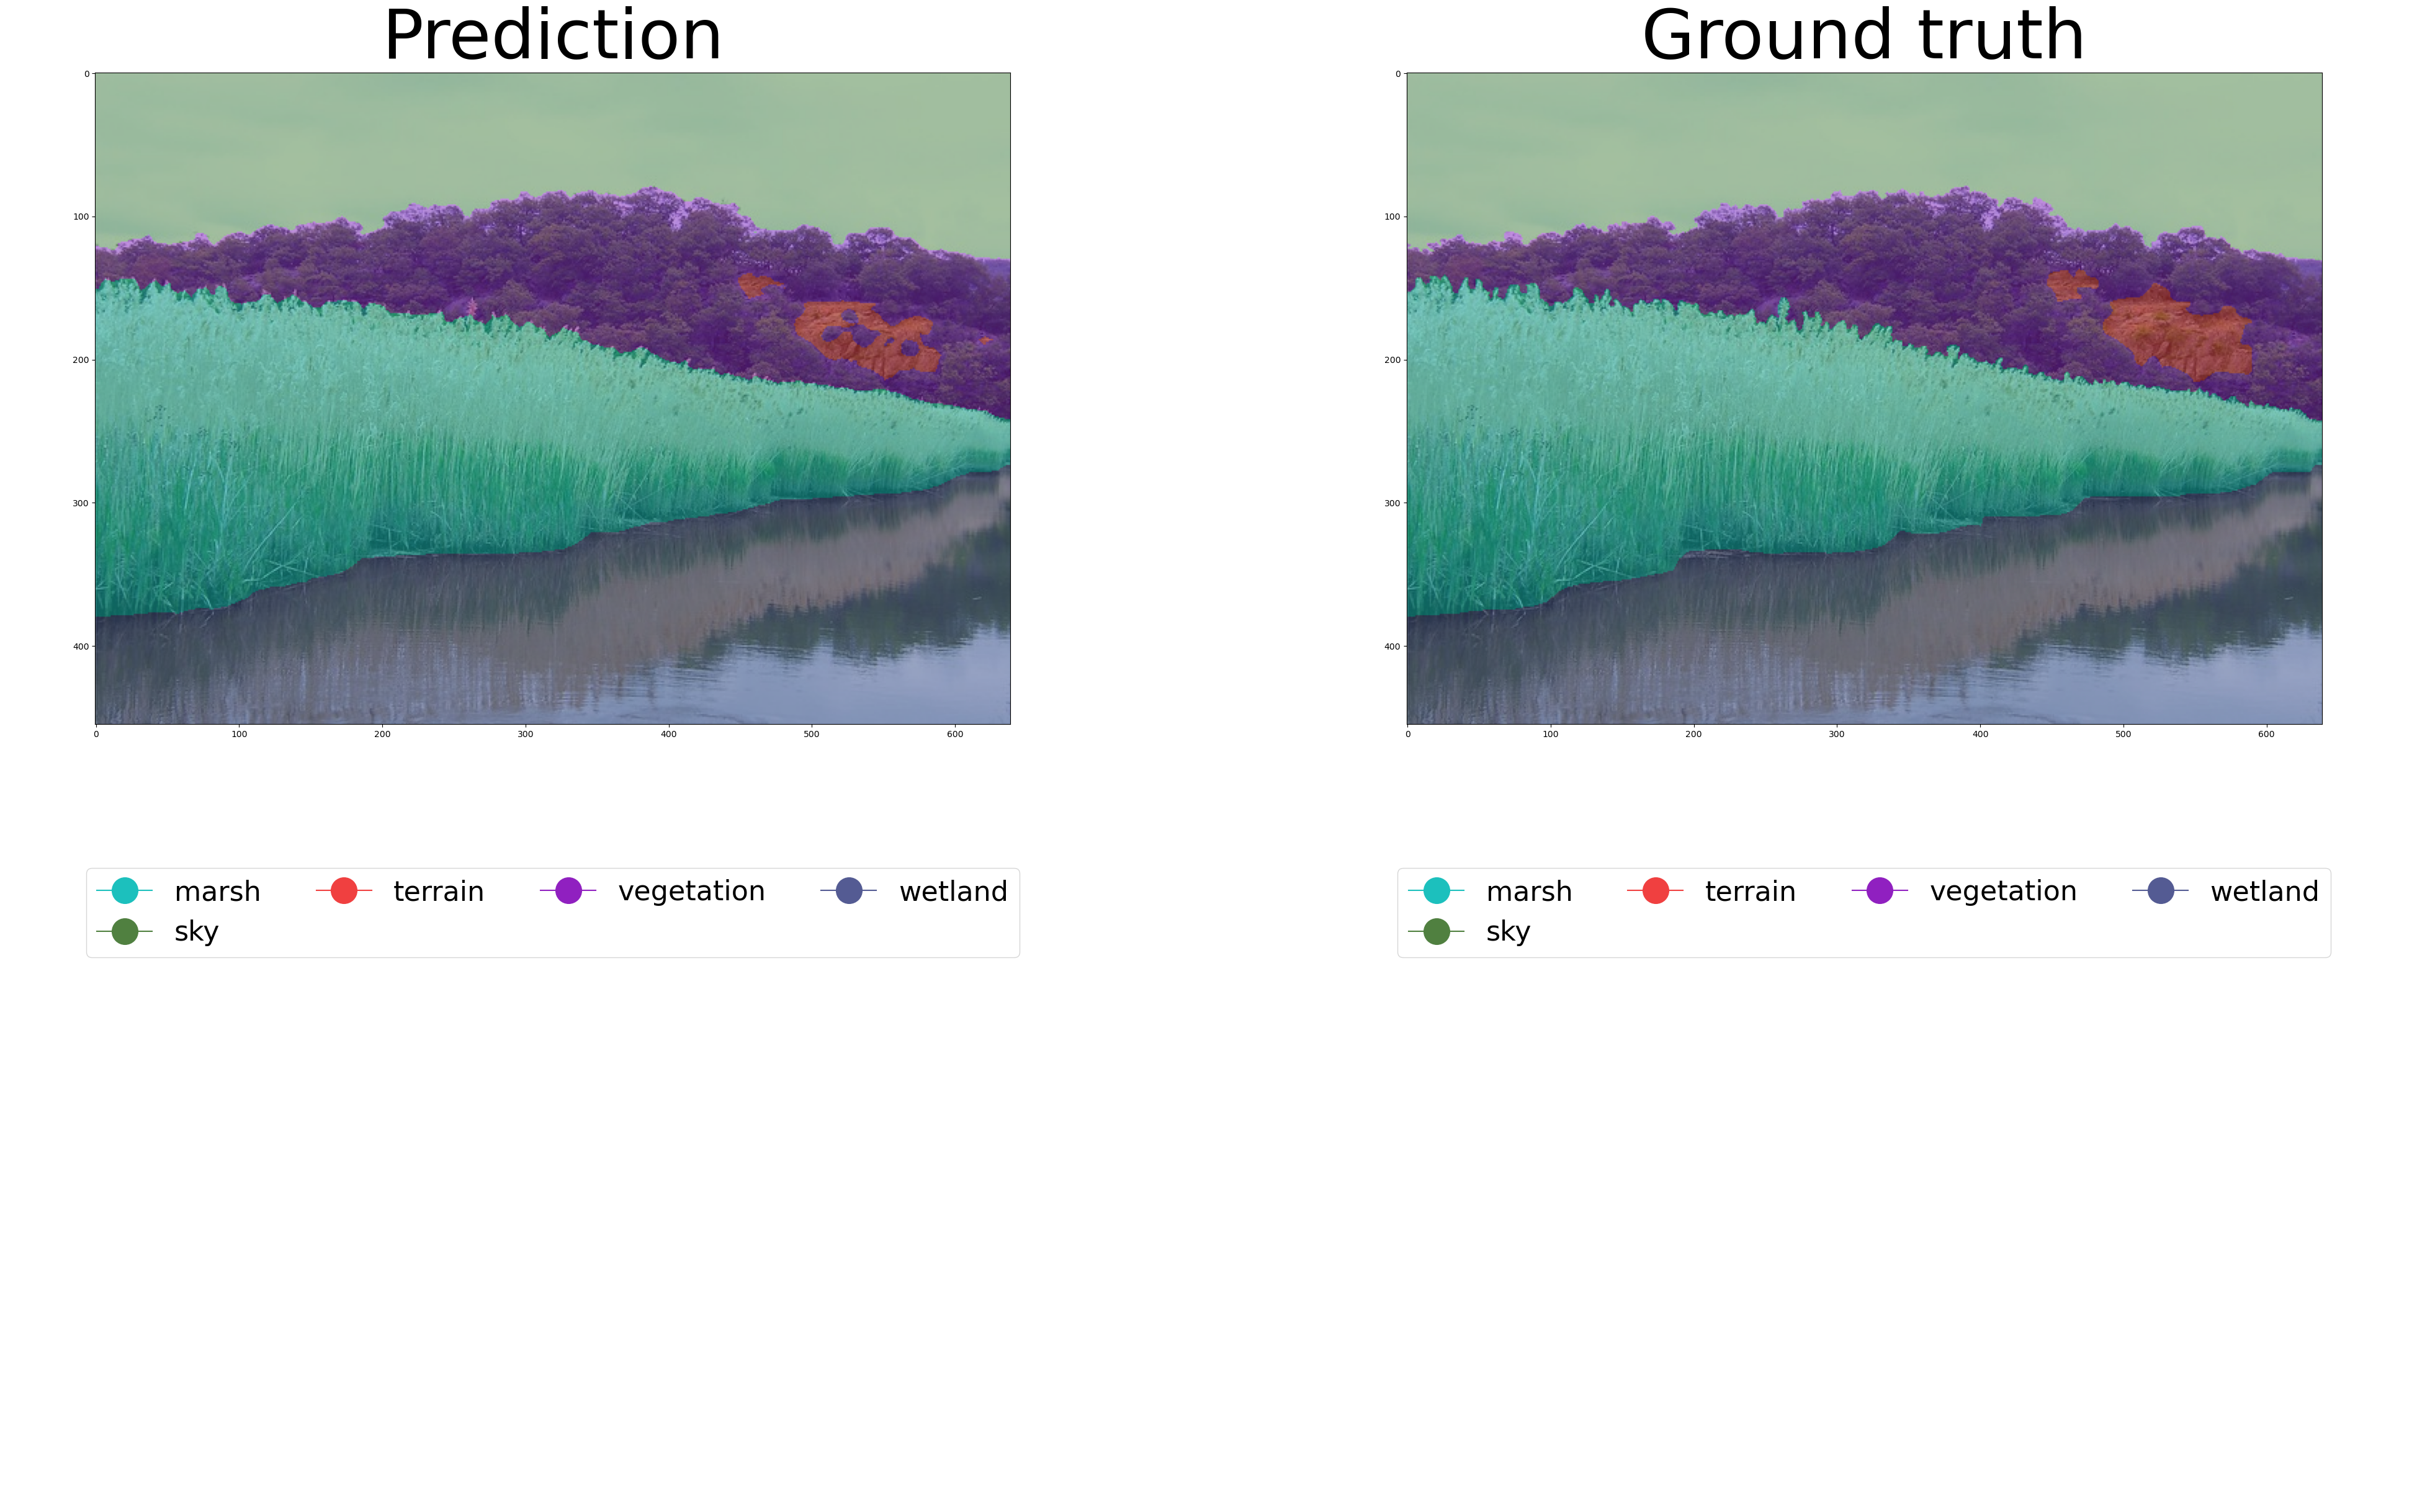

In [50]:
compare(test_ds, idx)